In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree  import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv(r"C:\Users\SuNi\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [4]:
df = df.drop(['customerID'], axis=1)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].apply(type).value_counts()

TotalCharges
<class 'float'>    7043
Name: count, dtype: int64

In [5]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].mean())
df.isnull().sum() 

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2265.000258
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1400.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


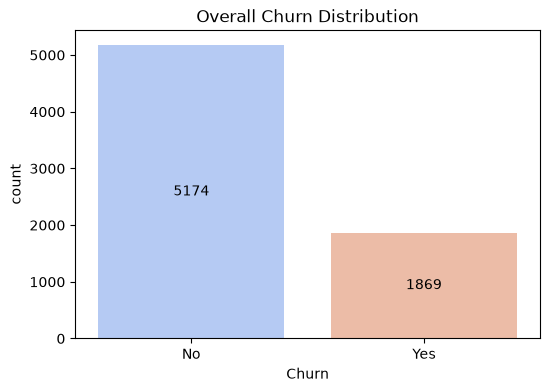

In [7]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=df['Churn'], palette='coolwarm')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Overall Churn Distribution')
plt.show()

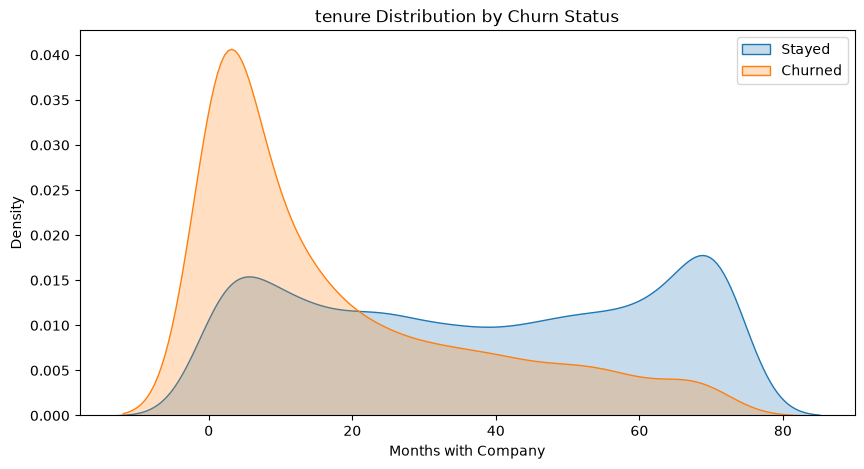

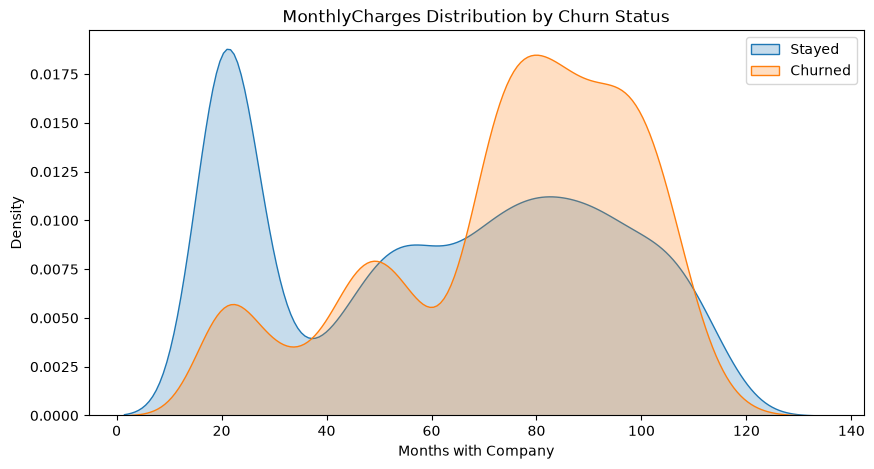

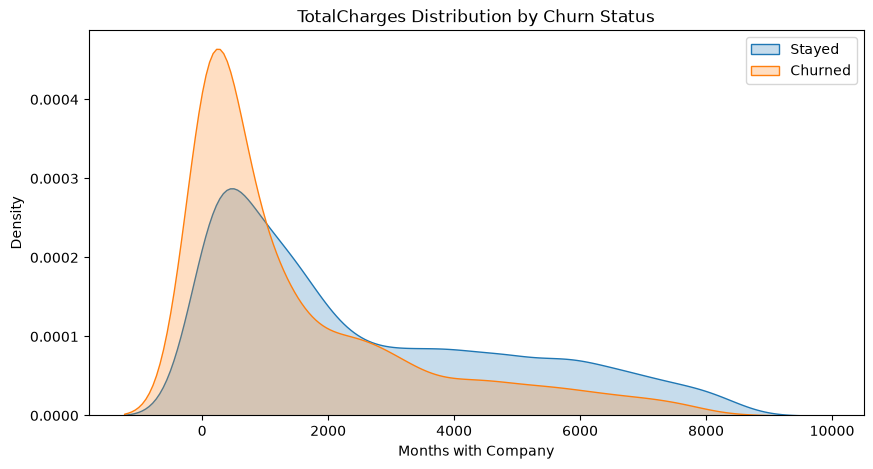

In [8]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    plt.figure(figsize=(10, 5))
    sns.kdeplot(df[df['Churn'] == 'No'][col], label='Stayed', shade=True)
    sns.kdeplot(df[df['Churn'] == 'Yes'][col], label='Churned', shade=True)
    plt.title(f'{col} Distribution by Churn Status')
    plt.xlabel('Months with Company')
    plt.legend()
    plt.show()

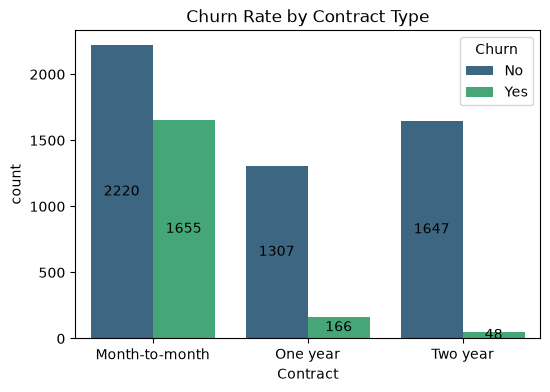

In [9]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Contract', data=df, hue='Churn', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Churn Rate by Contract Type')
plt.show()

In [10]:
word_cols = ['gender', 'Partner', 'Dependents', 'PhoneService','MultipleLines', 'InternetService',
'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
'Contract', 'PaperlessBilling', 'PaymentMethod','Churn']

for col in word_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

encoders = {}
for col in word_cols:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col].astype(str))

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


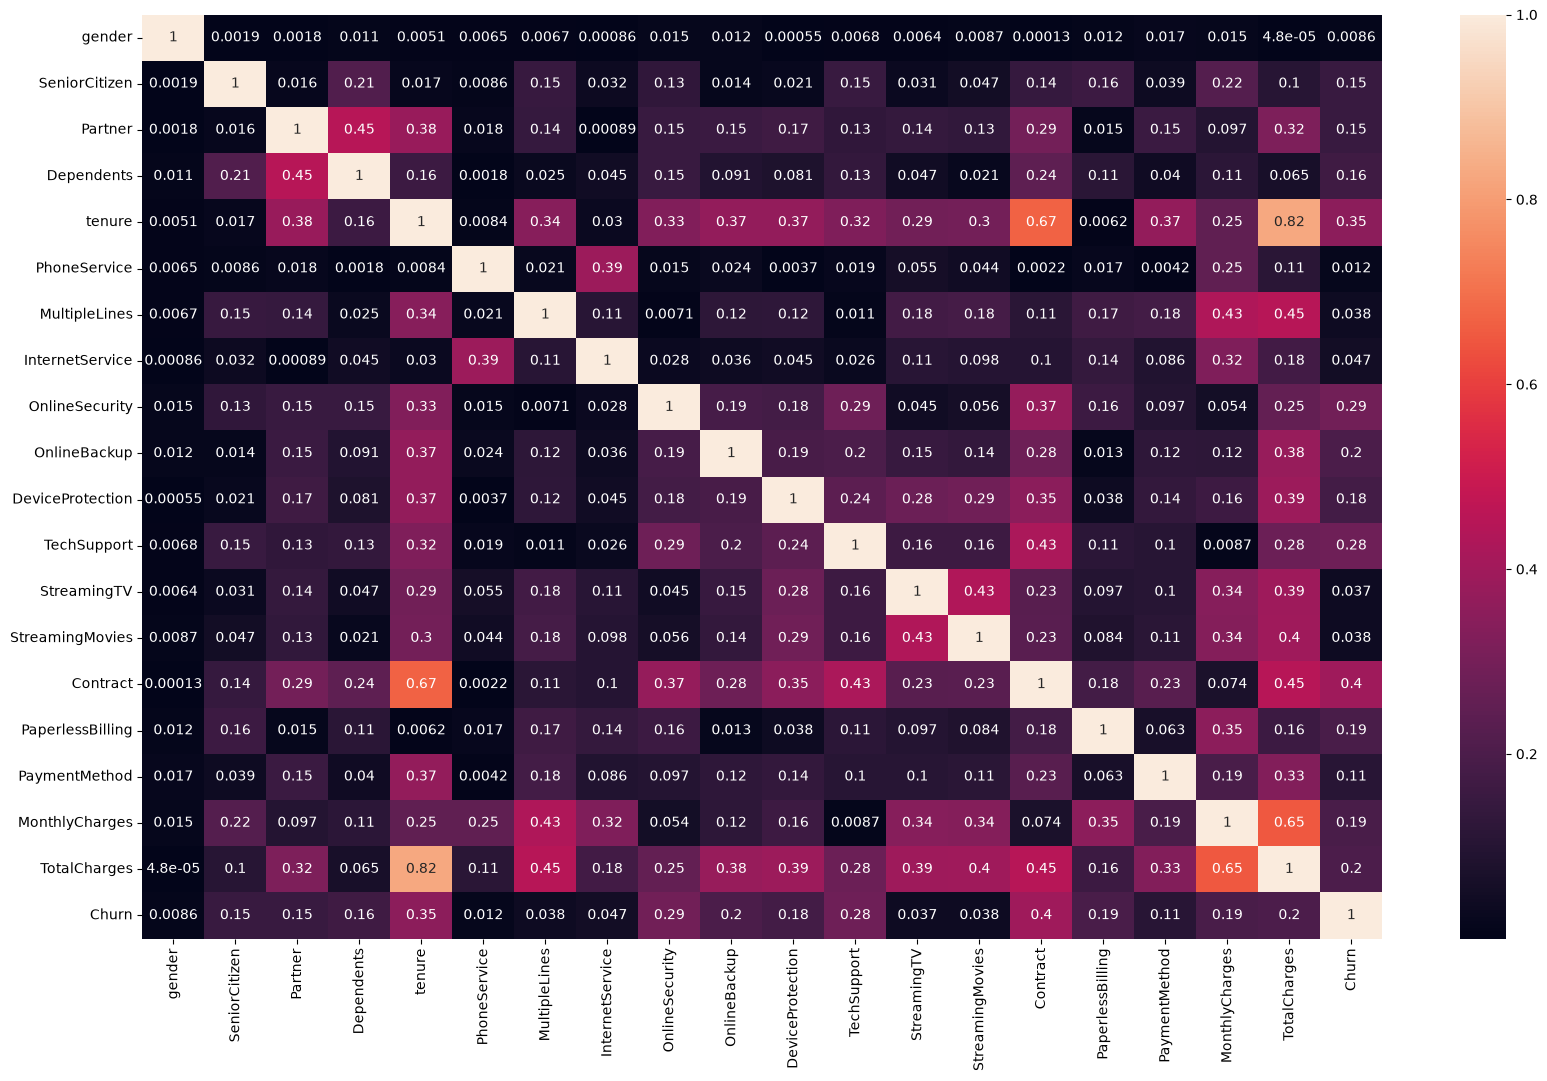

In [11]:
plt.figure(figsize=(20, 12))
corr = abs(df.corr(numeric_only=True))
sns.heatmap(corr, annot=True)
plt.show()

In [12]:
X = df.drop(['Churn'], axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.18, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

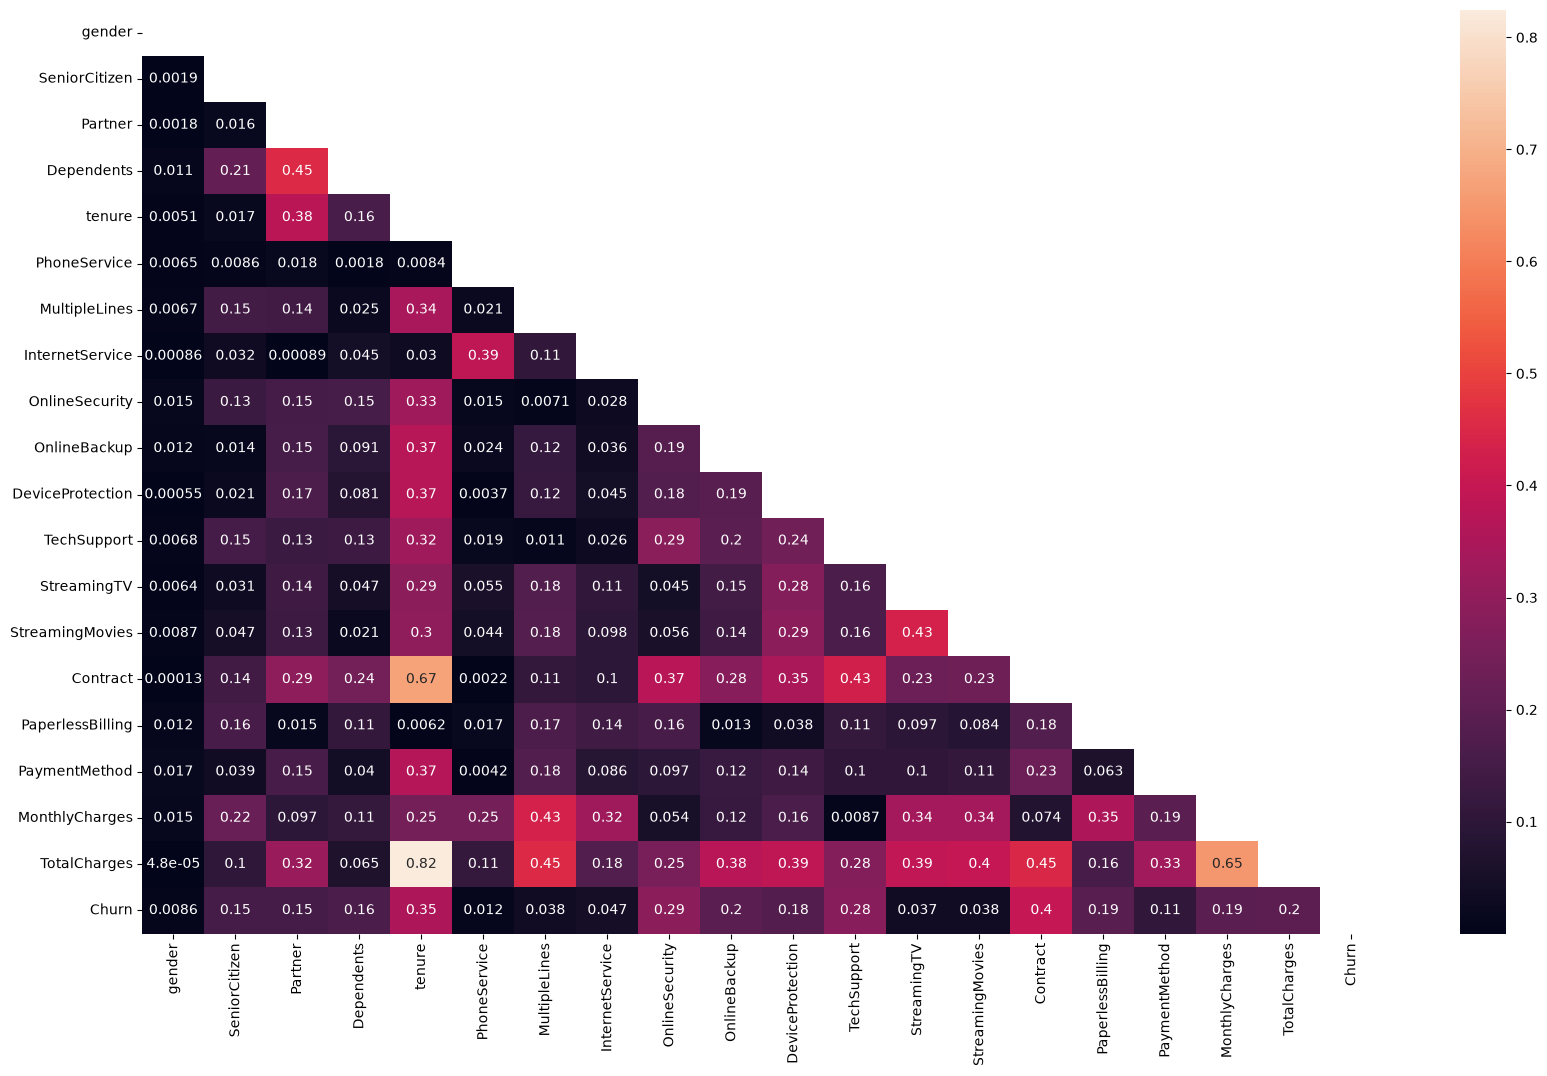

In [13]:
plt.figure(figsize=(20, 12))
corr = abs(df.corr(numeric_only=True))
mask = np.zeros_like(corr)
mask[np.triu_indices_from(mask)]=True
sns.heatmap(corr, annot=True, mask=mask)
plt.show()

In [14]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'K-Neighbors': KNeighborsClassifier(),
    'Gaussian NB': GaussianNB(),
    'XGBoost': XGBClassifier(),
    'SVM': LinearSVC()
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred=m.predict(X_test)
    pred_val=m.predict(X_val)
    print(f'\n---{name}---')
    print(f'Validation Accuracy:{accuracy_score(y_val, pred_val):.4f}')
    print(f"Overall Accuracy: {accuracy_score(y_test, pred):.4f}")
    print(f'Confusion Matrix:\n{confusion_matrix(y_test, pred)}')
    print(f'Classification Report:\n{classification_report(y_test, pred)}')


---Logistic Regression---
Validation Accuracy:0.8210
Overall Accuracy: 0.8202
Confusion Matrix:
[[697  78]
 [112 170]]
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       775
           1       0.69      0.60      0.64       282

    accuracy                           0.82      1057
   macro avg       0.77      0.75      0.76      1057
weighted avg       0.81      0.82      0.82      1057


---Decision Tree---
Validation Accuracy:0.7240
Overall Accuracy: 0.7171
Confusion Matrix:
[[627 148]
 [151 131]]
Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       775
           1       0.47      0.46      0.47       282

    accuracy                           0.72      1057
   macro avg       0.64      0.64      0.64      1057
weighted avg       0.72      0.72      0.72      1057


---Random Forest---
Validation Accuracy:0.7934
Overall Accuracy: 

In [15]:
model_names, model_acc_results, model_roc_results = [], [], []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    score = accuracy_score(y_test, preds)
    roc = roc_auc_score(y_test, preds)
    model_acc_results.append(score)
    model_roc_results.append(roc)
    model_names.append(name)

    df_results = pd.DataFrame([model_names, model_acc_results, model_roc_results])
    df_results = df_results.transpose()
    df_results = df_results.rename(columns={0: 'Model', 1: 'Accuracy', 2: 'ROC AUC'}).sort_values(by='Accuracy', ascending=False)

df_results

,Model,Accuracy,ROC AUC
6,SVM,0.825922,0.75835
0,Logistic Regression,0.820246,0.751096
2,Random Forest,0.788079,0.690812
5,XGBoost,0.781457,0.693063
4,Gaussian NB,0.760643,0.767973
3,K-Neighbors,0.759697,0.683864
1,Decision Tree,0.728477,0.66483


In [16]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        val_score = model.predict_proba(X_val)[:, 1]
    else:
        val_score = model.decision_function(X_val)

    results.append({
        'Model': name,
        'Val Accuracy': accuracy_score(y_val, val_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'ROC AUC': roc_auc_score(y_val, val_score),
    })

df_results = pd.DataFrame(results).sort_values(by='Val Accuracy', ascending=False)
df_results

,Model,Val Accuracy,Test Accuracy,ROC AUC
6,SVM,0.828076,0.825922,0.862029
0,Logistic Regression,0.820978,0.820246,0.863974
2,Random Forest,0.796530,0.793756,0.837560
5,XGBoost,0.787066,0.781457,0.831910
4,Gaussian NB,0.760252,0.760643,0.847872
3,K-Neighbors,0.758675,0.759697,0.777494
1,Decision Tree,0.727129,0.720908,0.646305
